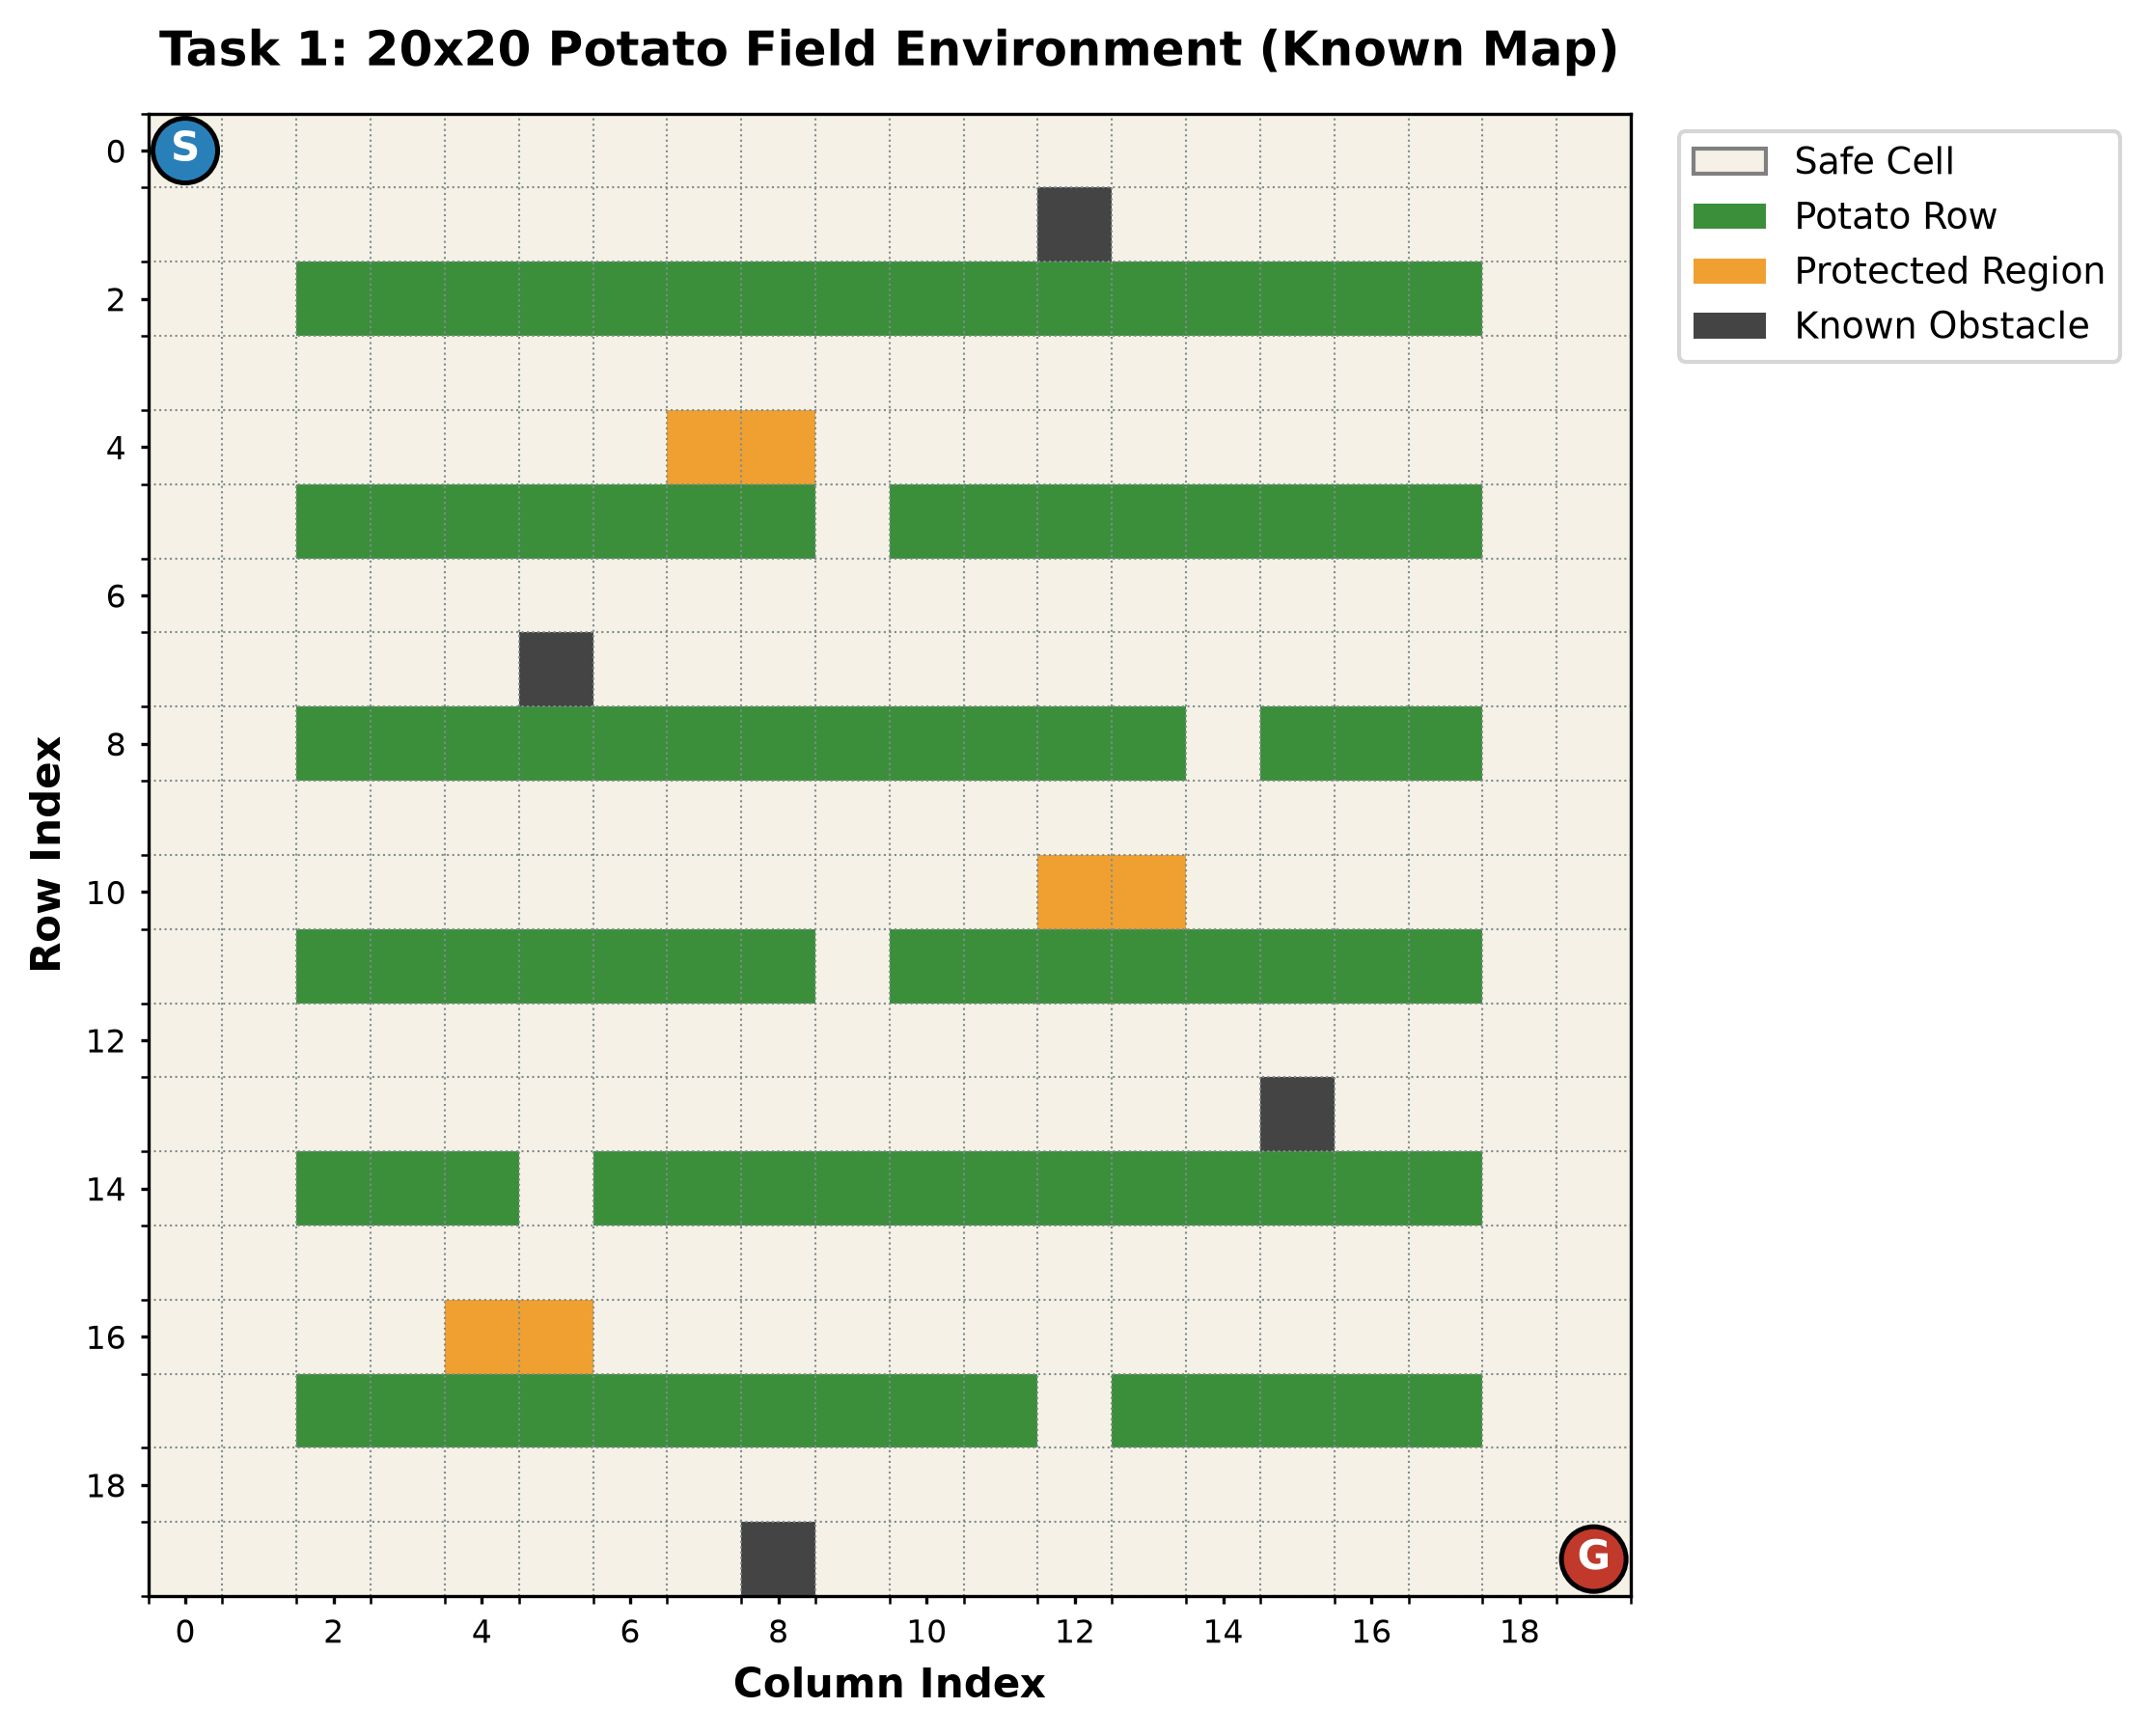

✓ Field environment successfully initialized and displayed.


In [1]:
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import Image, display
SAFE, POTATO, PROTECTED, OBSTACLE = (0, 1, 2, 3)
ROWS, COLS = (20, 20)
START = (0, 0)
GOAL = (19, 19)

def build_field():
    g = np.zeros((ROWS, COLS), dtype=int)
    for r in range(2, ROWS, 3):
        g[r, 2:18] = POTATO
    for r, c in [(5, 9), (8, 14), (11, 9), (14, 5), (17, 12)]:
        g[r, c] = SAFE
    for r, c in [(4, 7), (4, 8), (10, 12), (10, 13), (16, 4), (16, 5)]:
        g[r, c] = PROTECTED
    for r, c in [(1, 12), (7, 5), (13, 15), (19, 8)]:
        g[r, c] = OBSTACLE
    return g

def draw_field(grid, start=START, goal=GOAL, path=None, hidden=None, title='Potato Field Environment', ax=None, show_legend=True):
    cmap = ListedColormap(['#f5f1e6', '#3b8f3b', '#f0a030', '#444444'])
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 8), dpi=300)
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=3)
    ax.set_xticks(np.arange(-0.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, ROWS, 1), minor=True)
    ax.grid(which='minor', color='#7f8c8d', linewidth=0.5, linestyle=':')
    ax.set_xticks(range(0, COLS, 2))
    ax.set_yticks(range(0, ROWS, 2))
    ax.tick_params(which='both', length=2, labelsize=8)
    if hidden:
        hy, hx = zip(*hidden)
        ax.scatter(hx, hy, marker='X', c='#e74c3c', s=90, edgecolors='black', linewidths=1.2, zorder=5, label='Hidden Obstacles')
    if path:
        py, px = zip(*path)
        ax.plot(px, py, color='#2980b9', marker='o', markersize=3.5, linewidth=2.0, zorder=4, label='Planned Path')
    ax.text(start[1], start[0], 'S', ha='center', va='center', color='white', fontweight='bold', fontsize=10, bbox=dict(boxstyle='circle,pad=0.3', fc='#2980b9', ec='black', lw=1.2), zorder=6)
    ax.text(goal[1], goal[0], 'G', ha='center', va='center', color='white', fontweight='bold', fontsize=10, bbox=dict(boxstyle='circle,pad=0.3', fc='#c0392b', ec='black', lw=1.2), zorder=6)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Column Index', fontweight='bold')
    ax.set_ylabel('Row Index', fontweight='bold')
    if show_legend:
        handles = [Patch(fc='#f5f1e6', ec='gray', label='Safe Cell'), Patch(fc='#3b8f3b', label='Potato Row'), Patch(fc='#f0a030', label='Protected Region'), Patch(fc='#444444', label='Known Obstacle')]
        if hidden:
            handles.append(Patch(fc='#e74c3c', label='Hidden Obstacle'))
        ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=9, frameon=True)
    return ax
field_map = build_field()
fig, ax = plt.subplots(figsize=(7.5, 7.5), dpi=300)
draw_field(field_map, title='Task 1: 20x20 Potato Field Environment (Known Map)', ax=ax, show_legend=True)
plt.tight_layout()
plt.savefig('field_environment.png', bbox_inches='tight')
plt.close()
display(Image('field_environment.png'))
print('✓ Field environment successfully initialized and displayed.')

In [2]:
MOVES = {'U': (-1, 0), 'D': (1, 0), 'L': (0, -1), 'R': (0, 1)}
BLOCKED = {POTATO, PROTECTED, OBSTACLE}
PEN_ADJACENT = 5.0
PEN_NEAR = 2.0

def build_penalty_map(grid):
    pen = np.zeros(grid.shape, dtype=float)
    rows, cols = grid.shape
    prot = np.argwhere(grid == PROTECTED)
    for r in range(rows):
        for c in range(cols):
            if grid[r, c] in BLOCKED or len(prot) == 0:
                continue
            d = np.max(np.abs(prot - np.array([r, c])), axis=1).min()
            if d == 1:
                pen[r, c] = PEN_ADJACENT
            elif d == 2:
                pen[r, c] = PEN_NEAR
    return pen

class PathProblem:

    def __init__(self, grid, start=START, goal=GOAL, use_penalty=True):
        self.grid = grid
        self.start = start
        self.goal = goal
        self.use_penalty = use_penalty
        self.penalty = build_penalty_map(grid) if use_penalty else np.zeros(grid.shape)

    def in_bounds(self, s):
        return 0 <= s[0] < self.grid.shape[0] and 0 <= s[1] < self.grid.shape[1]

    def is_free(self, s):
        return self.in_bounds(s) and self.grid[s] not in BLOCKED

    def actions(self, s):
        return [a for a, (dr, dc) in MOVES.items() if self.is_free((s[0] + dr, s[1] + dc))]

    def result(self, s, a):
        dr, dc = MOVES[a]
        return (s[0] + dr, s[1] + dc)

    def goal_test(self, s):
        return s == self.goal

    def step_cost(self, s, a, s2):
        return 1.0 + self.penalty[s2]

    def path_cost(self, path):
        if not path or len(path) < 2:
            return 0.0
        return sum((1.0 + self.penalty[s] for s in path[1:]))
print('✓ Legal action transitions and Chebyshev proximity penalty model compiled.')

✓ Legal action transitions and Chebyshev proximity penalty model compiled.


In [3]:
def manhattan(s, goal):
    return abs(s[0] - goal[0]) + abs(s[1] - goal[1])
test_h = manhattan(START, GOAL)
print(f'✓ Manhattan heuristic verified: h(Start={START}, Goal={GOAL}) = {test_h} units.')

✓ Manhattan heuristic verified: h(Start=(0, 0), Goal=(19, 19)) = 38 units.


In [4]:
import time
from collections import deque

def reconstruct(parent, state):
    path = []
    while state is not None:
        path.append(state)
        state = parent[state]
    return path[::-1]

def make_result(name, prob, path, expanded, t0):
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    reached = path is not None and len(path) > 0 and prob.goal_test(path[-1])
    return {'name': name, 'reached': reached, 'path': path if reached else [], 'length': len(path) - 1 if reached else 0, 'cost': prob.path_cost(path) if reached else float('inf'), 'expanded': expanded, 'time_ms': elapsed_ms}

def bfs(prob):
    t0 = time.perf_counter()
    frontier = deque([prob.start])
    parent = {prob.start: None}
    expanded = 0
    while frontier:
        s = frontier.popleft()
        expanded += 1
        if prob.goal_test(s):
            return make_result('BFS', prob, reconstruct(parent, s), expanded, t0)
        for a in prob.actions(s):
            s2 = prob.result(s, a)
            if s2 not in parent:
                parent[s2] = s
                frontier.append(s2)
    return make_result('BFS', prob, None, expanded, t0)

def dfs(prob):
    t0 = time.perf_counter()
    frontier = [prob.start]
    parent = {prob.start: None}
    expanded = 0
    while frontier:
        s = frontier.pop()
        expanded += 1
        if prob.goal_test(s):
            return make_result('DFS', prob, reconstruct(parent, s), expanded, t0)
        for a in reversed(prob.actions(s)):
            s2 = prob.result(s, a)
            if s2 not in parent:
                parent[s2] = s
                frontier.append(s2)
    return make_result('DFS', prob, None, expanded, t0)
prob_test = PathProblem(build_field(), START, GOAL, use_penalty=True)
res_bfs = bfs(prob_test)
res_dfs = dfs(prob_test)
print(f"✓ BFS Execution: Length={res_bfs['length']}, Cost={res_bfs['cost']:.1f}, Expanded={res_bfs['expanded']}")
print(f"✓ DFS Execution: Length={res_dfs['length']}, Cost={res_dfs['cost']:.1f}, Expanded={res_dfs['expanded']}")

✓ BFS Execution: Length=38, Cost=50.0, Expanded=299
✓ DFS Execution: Length=108, Cost=177.0, Expanded=178


In [5]:
import heapq
import itertools

def greedy(prob):
    t0 = time.perf_counter()
    counter = itertools.count()
    h = lambda s: manhattan(s, prob.goal)
    frontier = [(h(prob.start), next(counter), prob.start)]
    parent = {prob.start: None}
    visited = set()
    expanded = 0
    while frontier:
        _, _, s = heapq.heappop(frontier)
        if s in visited:
            continue
        visited.add(s)
        expanded += 1
        if prob.goal_test(s):
            return make_result('Greedy', prob, reconstruct(parent, s), expanded, t0)
        for a in prob.actions(s):
            s2 = prob.result(s, a)
            if s2 not in visited and s2 not in parent:
                parent[s2] = s
                heapq.heappush(frontier, (h(s2), next(counter), s2))
    return make_result('Greedy', prob, None, expanded, t0)
res_greedy = greedy(prob_test)
print(f"✓ Greedy Search Execution: Length={res_greedy['length']}, Cost={res_greedy['cost']:.1f}, Expanded={res_greedy['expanded']}")

✓ Greedy Search Execution: Length=40, Cost=42.0, Expanded=41


✓ Crop-Safe A* Result: Length=38, Cost=38.0, Expanded=167
✓ Unpenalized A* Result: Length=38, Ground-Truth Cost=50.0


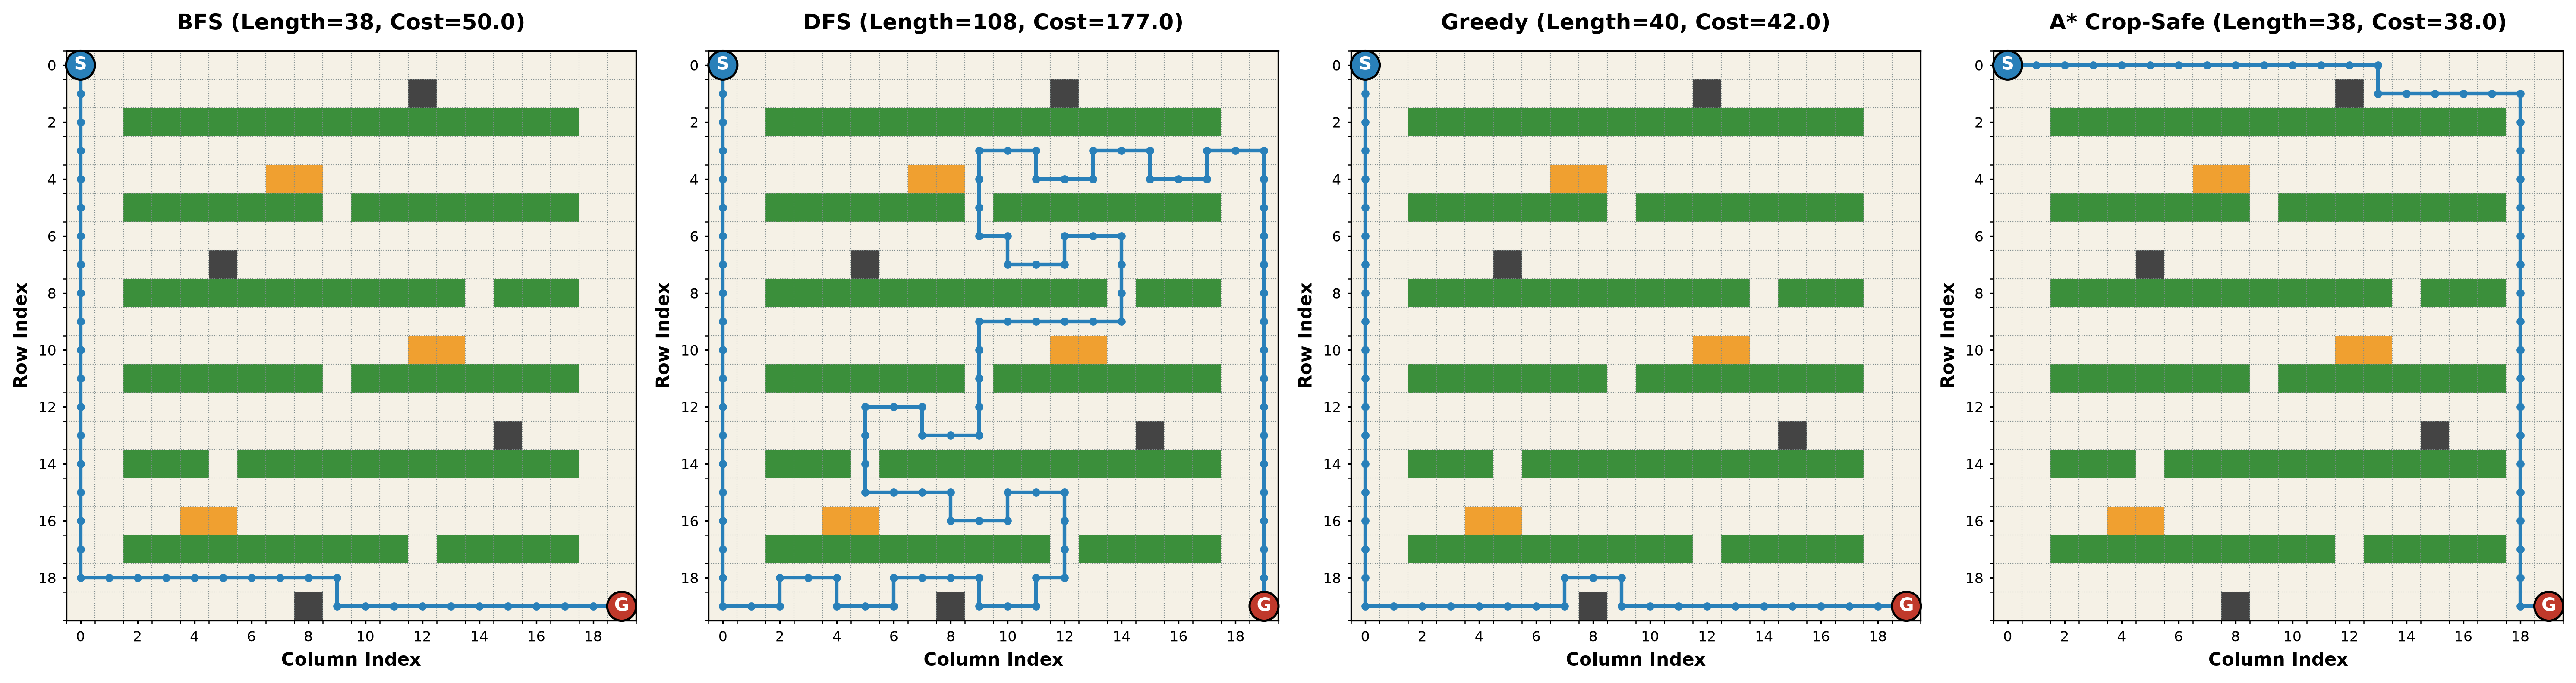

✓ Static route comparison chart saved and displayed.


In [6]:
def astar(prob):
    t0 = time.perf_counter()
    counter = itertools.count()
    h = lambda s: manhattan(s, prob.goal)
    g = {prob.start: 0.0}
    parent = {prob.start: None}
    frontier = [(h(prob.start), next(counter), prob.start)]
    expanded = 0
    while frontier:
        f_val, _, s = heapq.heappop(frontier)
        expanded += 1
        if prob.goal_test(s):
            return make_result('A*', prob, reconstruct(parent, s), expanded, t0)
        for a in prob.actions(s):
            s2 = prob.result(s, a)
            tentative_g = g[s] + prob.step_cost(s, a, s2)
            if s2 not in g or tentative_g < g[s2]:
                g[s2] = tentative_g
                parent[s2] = s
                heapq.heappush(frontier, (tentative_g + h(s2), next(counter), s2))
    return make_result('A*', prob, None, expanded, t0)
res_astar_pen = astar(prob_test)
prob_nopen = PathProblem(build_field(), START, GOAL, use_penalty=False)
res_astar_nopen = astar(prob_nopen)
print(f"✓ Crop-Safe A* Result: Length={res_astar_pen['length']}, Cost={res_astar_pen['cost']:.1f}, Expanded={res_astar_pen['expanded']}")
print(f"✓ Unpenalized A* Result: Length={res_astar_nopen['length']}, Ground-Truth Cost={prob_test.path_cost(res_astar_nopen['path']):.1f}")
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), dpi=300)
algos = [('BFS (Length=38, Cost=50.0)', res_bfs['path'], axes[0]), ('DFS (Length=108, Cost=177.0)', res_dfs['path'], axes[1]), ('Greedy (Length=40, Cost=42.0)', res_greedy['path'], axes[2]), ('A* Crop-Safe (Length=38, Cost=38.0)', res_astar_pen['path'], axes[3])]
for title, path, ax in algos:
    draw_field(field_map, path=path, title=title, ax=ax, show_legend=False)
plt.tight_layout()
plt.savefig('static_paths_comparison.png', bbox_inches='tight')
plt.close()
display(Image('static_paths_comparison.png'))
print('✓ Static route comparison chart saved and displayed.')

In [7]:
HIDDEN_OBSTACLES = [(9, 18), (9, 19)]

def sense(true_grid, known_grid, pos, rng=1):
    newly_discovered = []
    rows, cols = true_grid.shape
    for dr in range(-rng, rng + 1):
        for dc in range(-rng, rng + 1):
            r, c = (pos[0] + dr, pos[1] + dc)
            if 0 <= r < rows and 0 <= c < cols:
                if true_grid[r, c] == OBSTACLE and known_grid[r, c] != OBSTACLE:
                    known_grid[r, c] = OBSTACLE
                    newly_discovered.append((r, c))
    return newly_discovered
true_map = build_field()
for h in HIDDEN_OBSTACLES:
    true_map[h] = OBSTACLE
known_map = build_field()
blocked_waypoints = [h for h in HIDDEN_OBSTACLES if h in res_astar_pen['path']]
print(f'✓ Hidden obstacles placed at {HIDDEN_OBSTACLES}.')
print(f'✓ Initial A* trajectory intersects hidden obstacle waypoints: {blocked_waypoints}')

✓ Hidden obstacles placed at [(9, 18), (9, 19)].
✓ Initial A* trajectory intersects hidden obstacle waypoints: [(9, 18)]


=== Task 5: Dynamic Replanning Output ===
Goal Reached:        True
Replanning Events:   1 (Triggered at (8, 18))
Actual Journey:      Length=48, Cost=57.0
Total Expanded:      239 nodes


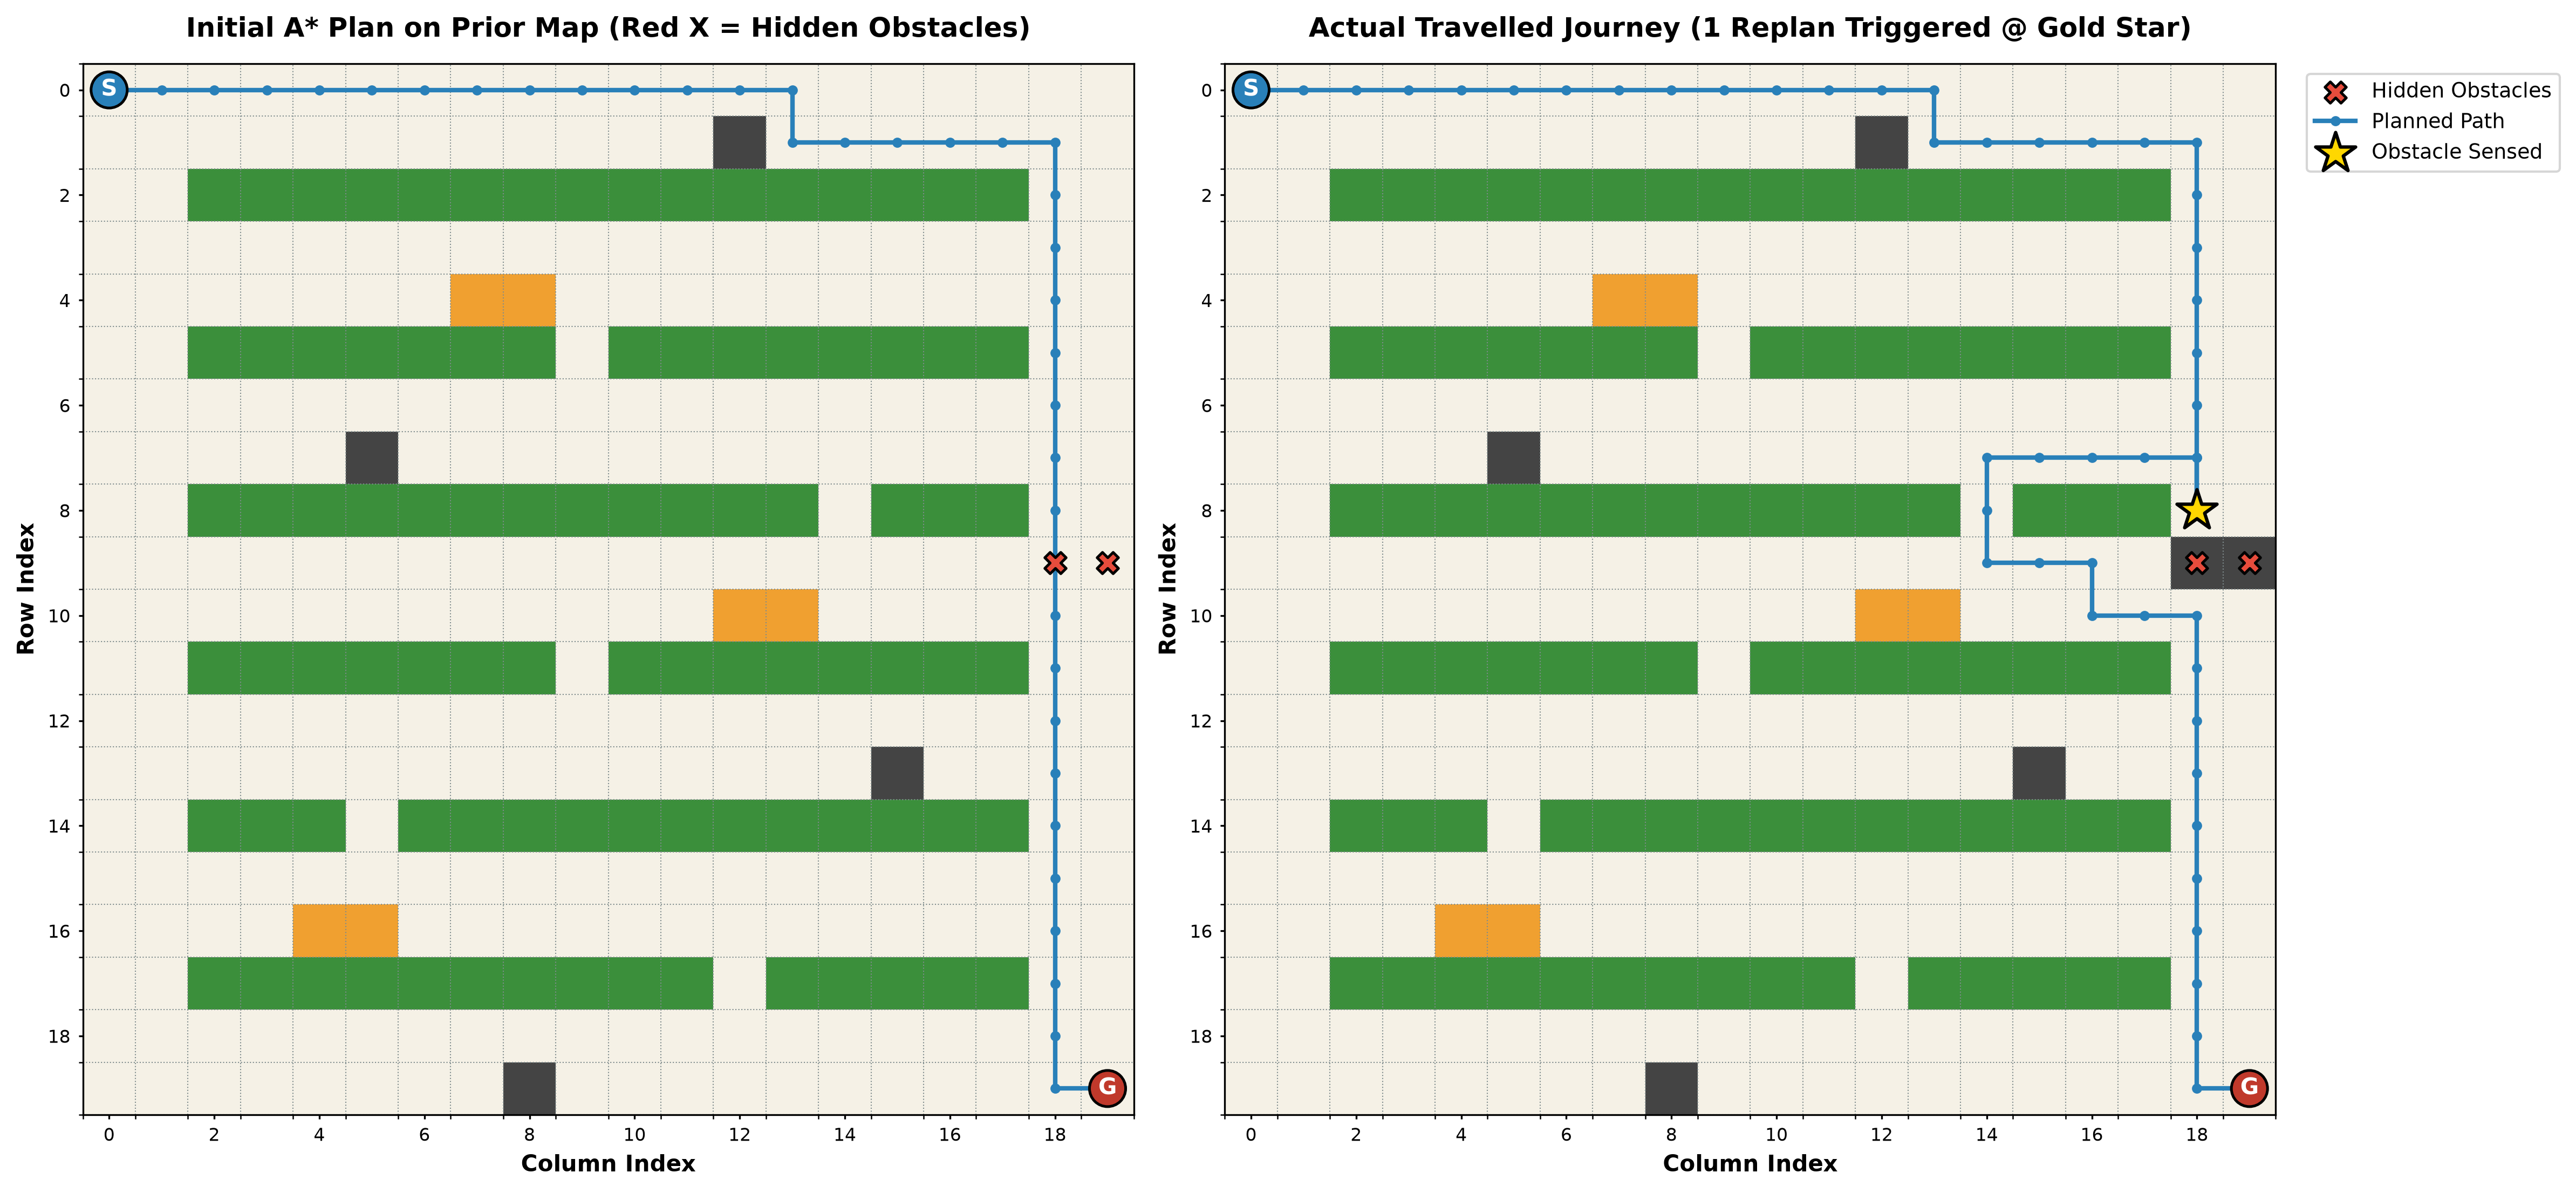

✓ Online reactive replanning demonstrated and saved to online_replanning_demo.png.


In [8]:
def run_with_replanning(true_grid, initial_known, start=START, goal=GOAL, planner=astar, rng=1):
    t0 = time.perf_counter()
    known = initial_known.copy()
    pos = start
    travelled = [pos]
    events = []
    replans = 0
    expanded_total = 0
    plan_res = planner(PathProblem(known, pos, goal))
    expanded_total += plan_res['expanded']
    if not plan_res['reached']:
        return {'reached': False, 'expanded': expanded_total, 'time_ms': (time.perf_counter() - t0) * 1000}
    initial_path = plan_res['path']
    plan = list(initial_path)
    sense(true_grid, known, pos, rng)
    step_limit = 500
    steps = 0
    while pos != goal and steps < step_limit:
        steps += 1
        if not plan or plan[0] != pos:
            break
        nxt = plan[1]
        newly = sense(true_grid, known, pos, rng)
        if newly:
            events.append((pos, newly))
            replan_needed = any((obs in plan[1:] for obs in newly))
            if replan_needed:
                replans += 1
                res = planner(PathProblem(known, pos, goal))
                expanded_total += res['expanded']
                if not res['reached']:
                    break
                plan = list(res['path'])
                nxt = plan[1]
        pos = nxt
        plan = plan[1:]
        travelled.append(pos)
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    reached = pos == goal
    cost_model = PathProblem(known, start, goal)
    return {'reached': reached, 'initial_path': initial_path, 'travelled': travelled, 'final_known': known, 'events': events, 'replans': replans, 'length': len(travelled) - 1, 'cost': cost_model.path_cost(travelled), 'expanded': expanded_total, 'time_ms': elapsed_ms}
res_replan = run_with_replanning(true_map, known_map, START, GOAL, planner=astar)
print('=== Task 5: Dynamic Replanning Output ===')
print(f"Goal Reached:        {res_replan['reached']}")
print(f"Replanning Events:   {res_replan['replans']} (Triggered at {res_replan['events'][0][0]})")
print(f"Actual Journey:      Length={res_replan['length']}, Cost={res_replan['cost']:.1f}")
print(f"Total Expanded:      {res_replan['expanded']} nodes")
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), dpi=300)
draw_field(field_map, path=res_replan['initial_path'], hidden=HIDDEN_OBSTACLES, ax=axes[0], show_legend=False, title='Initial A* Plan on Prior Map (Red X = Hidden Obstacles)')
draw_field(res_replan['final_known'], path=res_replan['travelled'], hidden=HIDDEN_OBSTACLES, ax=axes[1], show_legend=False, title=f"Actual Travelled Journey ({res_replan['replans']} Replan Triggered @ Gold Star)")
for pos, _ in res_replan['events']:
    axes[1].scatter(pos[1], pos[0], marker='*', s=350, c='gold', edgecolors='black', linewidths=1.5, zorder=7, label='Obstacle Sensed')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), fontsize=9)
plt.tight_layout()
plt.savefig('online_replanning_demo.png', bbox_inches='tight')
plt.close()
display(Image('online_replanning_demo.png'))
print('✓ Online reactive replanning demonstrated and saved to online_replanning_demo.png.')

=== TABLE 1: Static Map Performance Benchmark ===


,Algorithm,Reached,Path Length,Path Cost,Expanded Nodes,Execution Time (ms)
0,BFS,True,38,50.0,299,0.614
1,DFS,True,108,177.0,178,0.372
2,Greedy Best-First,True,40,42.0,41,0.109
3,A* (Crop-Safe),True,38,38.0,167,0.587
4,A* (No Penalty),True,38,50.0,299,1.007



=== TABLE 2: Online Obstacle Replanning Performance Benchmark ===


,Planner,Reached,Journey Length,Journey Cost,Replanning Ops,Total Expanded,Execution Time (ms)
0,BFS,True,38,50.0,0,299,2.263
1,DFS,True,208,328.0,1,379,3.552
2,Greedy Best-First,True,40,42.0,0,41,1.074
3,A* (Crop-Safe),True,48,57.0,1,239,2.497


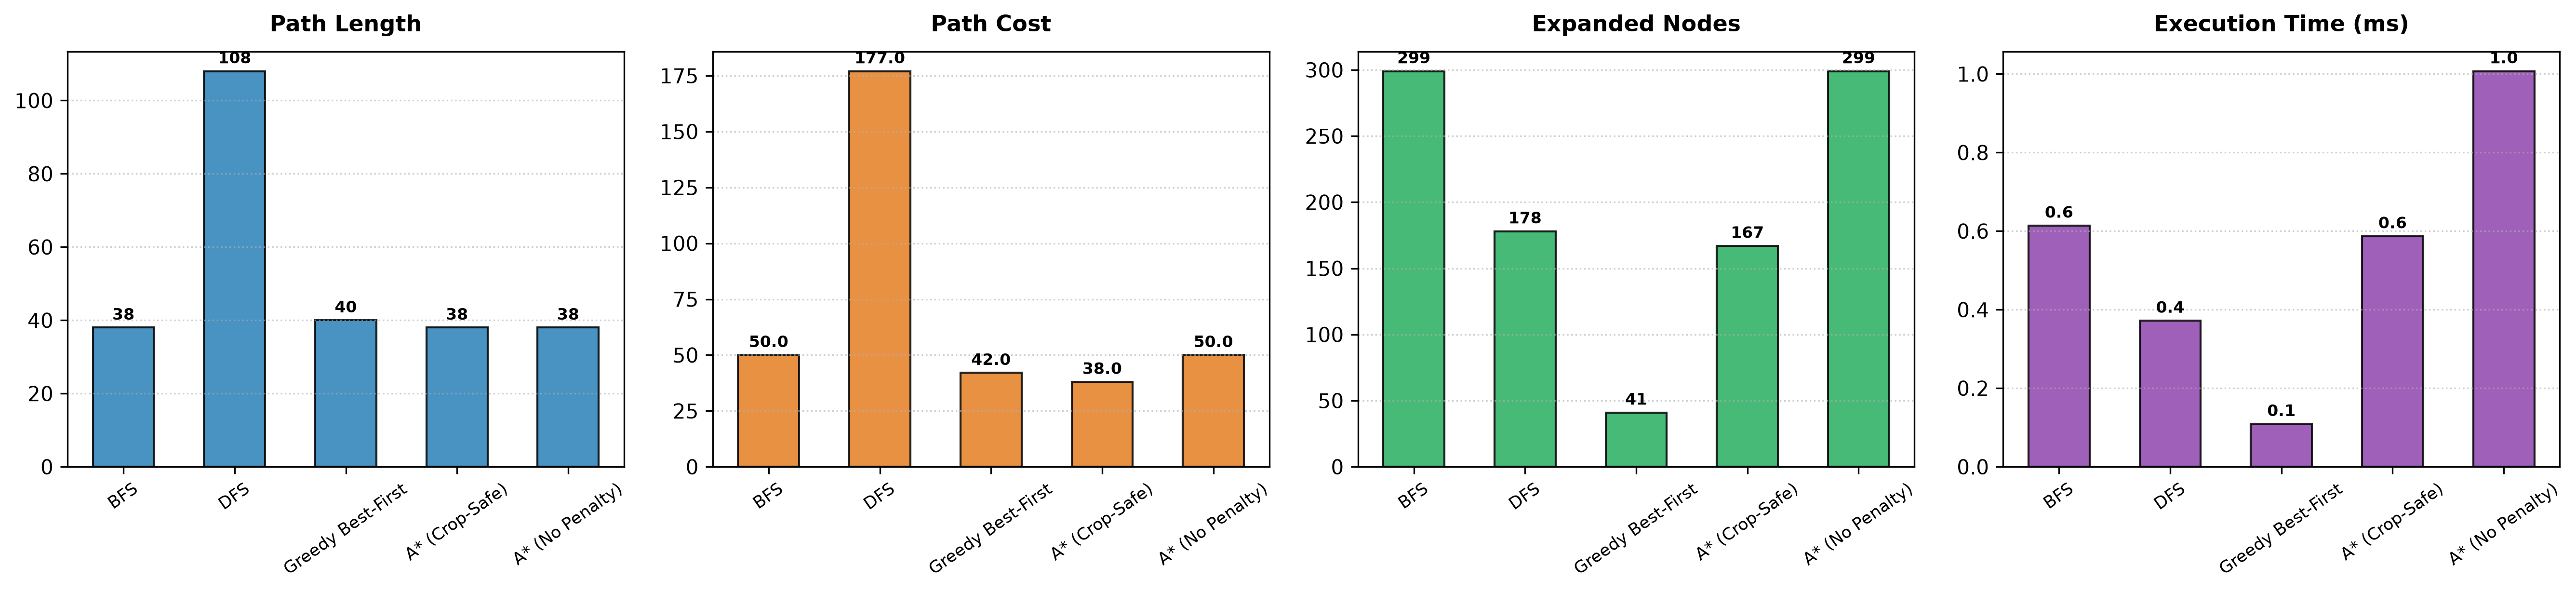

✓ Benchmark tables exported to CSV and 4-panel comparison chart rendered.


In [9]:
import pandas as pd
N_RUNS = 100
N_ONLINE_RUNS = 20

def benchmark_static(fn, prob, n=N_RUNS):
    times = []
    for _ in range(n):
        r = fn(prob)
        times.append(r['time_ms'])
    r['time_ms'] = sum(times) / len(times)
    return r
static_rows = []
for name, fn in [('BFS', bfs), ('DFS', dfs), ('Greedy Best-First', greedy), ('A* (Crop-Safe)', astar)]:
    r = benchmark_static(fn, prob_test)
    static_rows.append([name, r['reached'], r['length'], r['cost'], r['expanded'], r['time_ms']])
r_np = benchmark_static(astar, prob_nopen)
static_rows.append(['A* (No Penalty)', r_np['reached'], r_np['length'], prob_test.path_cost(r_np['path']), r_np['expanded'], r_np['time_ms']])
df_static = pd.DataFrame(static_rows, columns=['Algorithm', 'Reached', 'Path Length', 'Path Cost', 'Expanded Nodes', 'Execution Time (ms)'])
df_static['Path Cost'] = df_static['Path Cost'].round(1)
df_static['Execution Time (ms)'] = df_static['Execution Time (ms)'].round(3)
df_static.to_csv('results_static.csv', index=False)
online_rows = []
for name, fn in [('BFS', bfs), ('DFS', dfs), ('Greedy Best-First', greedy), ('A* (Crop-Safe)', astar)]:
    times = []
    for _ in range(N_ONLINE_RUNS):
        res = run_with_replanning(true_map, known_map, START, GOAL, planner=fn)
        times.append(res['time_ms'])
    online_rows.append([name, res['reached'], res['length'], res['cost'], res['replans'], res['expanded'], sum(times) / len(times)])
df_online = pd.DataFrame(online_rows, columns=['Planner', 'Reached', 'Journey Length', 'Journey Cost', 'Replanning Ops', 'Total Expanded', 'Execution Time (ms)'])
df_online['Journey Cost'] = df_online['Journey Cost'].round(1)
df_online['Execution Time (ms)'] = df_online['Execution Time (ms)'].round(3)
df_online.to_csv('results_online.csv', index=False)
print('=== TABLE 1: Static Map Performance Benchmark ===')
display(df_static)
print('\n=== TABLE 2: Online Obstacle Replanning Performance Benchmark ===')
display(df_online)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), dpi=300)
metrics = [('Path Length', '#2980b9'), ('Path Cost', '#e67e22'), ('Expanded Nodes', '#27ae60'), ('Execution Time (ms)', '#8e44ad')]
for ax, (metric, color) in zip(axes, metrics):
    bars = ax.bar(df_static['Algorithm'], df_static[metric], color=color, edgecolor='black', alpha=0.85, width=0.55)
    ax.set_title(metric, fontsize=11, fontweight='bold', pad=10)
    ax.tick_params(axis='x', rotation=35, labelsize=8.5)
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + max(df_static[metric]) * 0.02, f'{h:.1f}' if isinstance(h, float) else f'{int(h)}', ha='center', fontsize=8, fontweight='bold')
plt.tight_layout()
plt.savefig('performance_comparison.png', bbox_inches='tight')
plt.close()
display(Image('performance_comparison.png'))
print('✓ Benchmark tables exported to CSV and 4-panel comparison chart rendered.')